# Inference IMDB — Jev (TypeSafe AI) + comparison with all modalities

1. Calls **Jev** (TypeSafe AI, System One model) through its HTTP API — zero-shot, one `choice` question per review.
2. Predicts the 25,000 IMDB test reviews (same `df_test_{1..5}.csv` files and order as the other notebooks).
3. Compares Jev against: **BERT** (classifier), **Mistral-7B classifier (LoRA)**, **Mistral-7B base zero-shot generative** and **Mistral-7B generative finetuning (LoRA)**.

Requirements: a `TYPESAFE_API_KEY` stored in Colab secrets. No GPU needed.

In [1]:
import time
start_notebook = time.time()

In [2]:
import warnings
warnings.filterwarnings("ignore")

# 1. Parameters

In [3]:
name_dataset = 'IMDB'
seed = 1
parts = [1, 2, 3, 4, 5]
folder_llm = 'Mistral-7B-v0.3'

In [4]:
# Jev
JEV_MODEL = 'jev-latest'          # or pin a version, e.g. 'jev-1.13' (recommended for reproducibility)
JEV_URL = 'https://api.typesafe.ai/v1/systemone'
MAX_WORKERS = 8                   # parallel requests; lower it if you hit many 429s
MAX_RETRIES = 6
TIMEOUT_S = 60
N_SAMPLE = None                   # None = full test set (25,000). Use e.g. 500 for a quick, cheap run
PRICE_PER_M_INPUT = 0.042         # USD per 1M input tokens (check current pricing)

In [5]:
base = f'/content/drive/MyDrive/Finetuned-encoders-LLM-Prompting'
path_open = f'{base}/01.Datasets_Creation/{name_dataset}'
path_inference = f'{base}/03.Inference/{name_dataset}/post1'

path_save = f'{path_inference}/df_test_all_jev.csv'
path_cache = f'{path_inference}/jev_cache_{JEV_MODEL}.jsonl'     # lets you resume if the run stops

# Results of the other notebooks (used for the comparison)
path_classification = f'{path_inference}/df_test_all.csv'               # BERT + Mistral classifier
path_generative = f'{path_inference}/df_test_all_generative.csv'        # Mistral base + generative LoRA

In [6]:
col_jev = JEV_MODEL   # e.g. 'jev-latest'

# 2. Load Environment

In [7]:
!pip install -q requests statsmodels

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
import json
import random
import threading
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.metrics import classification_report, f1_score, accuracy_score, precision_score, recall_score, roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar

In [10]:
from google.colab import userdata
TYPESAFE_API_KEY = userdata.get('TYPESAFE_API_KEY')
assert TYPESAFE_API_KEY, 'Add TYPESAFE_API_KEY to Colab secrets'

# 3. Load Dataset

In [11]:
list_df = []

for part in parts:
  df_part = pd.read_csv(f'{path_open}/df_test_{part}.csv')
  list_df.append(df_part)

df = pd.concat(list_df, ignore_index = True)
df.shape

(25000, 3)

In [12]:
# Optional subset (stratified-free random sample, fixed seed). Comparison uses the same rows for every model.
if N_SAMPLE is not None:
  idx_eval = df.sample(n = N_SAMPLE, random_state = seed).index.sort_values()
else:
  idx_eval = df.index
print(len(idx_eval), 'reviews to evaluate')

25000 reviews to evaluate


# 4. Jev request

Jev does not generate text: it receives a **state** (the review) and **typed questions**, and returns a decision with probabilities.
We ask one `choice` question with two options. The instruction mirrors the prompt used in the Mistral generative notebook, so the task definition is the same.

In [13]:
INSTRUCTION = (
    "Read the following movie review and decide whether the sentiment it expresses "
    "is positive or negative."
)

CRITERIA = {
    "positive": "The reviewer's overall opinion of the movie is favorable.",
    "negative": "The reviewer's overall opinion of the movie is unfavorable.",
}

WORD2LABEL = {"negative": 0, "positive": 1}

def build_payload(review):
  return {
      "model": JEV_MODEL,
      "state": review,
      "questions": {
          "sentiment": {
              "type": "choice",
              "instructions": INSTRUCTION,
              "criteria": CRITERIA,
          }
      },
  }

In [14]:
session = requests.Session()
session.headers.update({
    "Authorization": f"Bearer {TYPESAFE_API_KEY}",
    "Content-Type": "application/json",
})

RETRY_STATUS = {408, 409, 429, 500, 502, 503, 504}

def call_jev(review):
  """POST one review to Jev with retries. Returns (json, latency_ms of the successful call)."""
  payload = build_payload(review)
  for attempt in range(MAX_RETRIES):
    try:
      start = time.perf_counter()
      r = session.post(JEV_URL, json = payload, timeout = TIMEOUT_S)
      latency = (time.perf_counter() - start) * 1000
      if r.status_code == 200:
        return r.json(), latency
      if r.status_code not in RETRY_STATUS:
        raise RuntimeError(f'HTTP {r.status_code}: {r.text[:300]}')
      wait = float(r.headers.get('Retry-After', 0)) or min(60, 2 ** attempt + random.random())
    except (requests.ConnectionError, requests.Timeout):
      wait = min(60, 2 ** attempt + random.random())
    time.sleep(wait)
  raise RuntimeError(f'Failed after {MAX_RETRIES} retries')

In [15]:
def _probs_to_dict(probs):
  """Accept probabilities as {option: p} or [{'option'/'name': .., 'probability'/'p': ..}]."""
  if isinstance(probs, dict):
    return {k: float(v) for k, v in probs.items()}
  out = {}
  if isinstance(probs, list):
    for item in probs:
      if isinstance(item, dict):
        k = item.get('option', item.get('name', item.get('choice')))
        v = item.get('probability', item.get('p', item.get('value')))
        if k is not None and v is not None:
          out[k] = float(v)
  return out

def parse_jev(resp):
  """Map Jev's answer to: label (1 = positive, 0 = negative, -1 = invalid), p_positive, confidence."""
  ans = (resp.get('answers') or {}).get('sentiment') or {}
  choice = str(ans.get('choice', '')).strip().lower()
  probs = _probs_to_dict(ans.get('probabilities'))
  p_pos = probs.get('positive')
  if p_pos is None and 'negative' in probs:
    p_pos = 1 - probs['negative']
  return {
      'label': WORD2LABEL.get(choice, -1),
      'p_positive': p_pos,
      'confidence': ans.get('confidence'),
      'model_version': resp.get('model'),
      'input_tokens': (resp.get('usage') or {}).get('input_tokens'),
      'server_ms': resp.get('elapsed_ms'),
  }

### Smoke test
Check the raw response shape before launching 25k requests. If `label` is `-1` here, adapt `parse_jev` to the printed JSON.

In [16]:
for i in [0, len(df) - 1]:
  resp, lat = call_jev(df['text'].iloc[i])
  print('true label:', df['label'].iloc[i], '| latency:', round(lat, 1), 'ms')
  print(json.dumps(resp, indent = 2)[:1500])
  print(parse_jev(resp))
  print('-' * 70)

true label: 0 | latency: 105.4 ms
{
  "model": "jev-1.14.0",
  "answers": {
    "sentiment": {
      "type": "choice",
      "choice": "negative",
      "confidence": 1.0,
      "probabilities": {
        "positive": 0.0,
        "negative": 1.0
      }
    }
  },
  "usage": {
    "input_tokens": 657,
    "output_tokens": 32
  }
}
{'label': 0, 'p_positive': 0.0, 'confidence': 1.0, 'model_version': 'jev-1.14.0', 'input_tokens': 657, 'server_ms': None}
----------------------------------------------------------------------
true label: 1 | latency: 51.3 ms
{
  "model": "jev-1.14.0",
  "answers": {
    "sentiment": {
      "type": "choice",
      "choice": "positive",
      "confidence": 1.0,
      "probabilities": {
        "positive": 1.0,
        "negative": 0.0
      }
    }
  },
  "usage": {
    "input_tokens": 507,
    "output_tokens": 32
  }
}
{'label': 1, 'p_positive': 1.0, 'confidence': 1.0, 'model_version': 'jev-1.14.0', 'input_tokens': 507, 'server_ms': None}
--------------------

# 5. Inference (parallel, resumable)
Each result is appended to a JSONL cache on Drive, so if Colab disconnects you just re-run this cell.

In [17]:
cache = {}
if os.path.exists(path_cache):
  with open(path_cache) as f:
    for line in f:
      rec = json.loads(line)
      cache[rec['idx']] = rec
print('Cached results:', len(cache))

lock = threading.Lock()
pending = [i for i in idx_eval if i not in cache]
print('Pending:', len(pending))

def work(i):
  resp, lat = call_jev(df['text'].iloc[i])
  rec = {'idx': int(i), 'latency': lat, **parse_jev(resp)}
  with lock:
    with open(path_cache, 'a') as f:
      f.write(json.dumps(rec) + '\n')
    cache[int(i)] = rec
  return rec

errors = []
start_inf = time.time()
with ThreadPoolExecutor(max_workers = MAX_WORKERS) as ex:
  futures = {ex.submit(work, i): i for i in pending}
  for n, fut in enumerate(as_completed(futures), 1):
    try:
      fut.result()
    except Exception as e:
      errors.append((futures[fut], str(e)))
    if n % 500 == 0:
      el = time.time() - start_inf
      print(f'{n}/{len(pending)}  |  {n/el:.1f} req/s  |  errors: {len(errors)}')

print('Done. Errors:', len(errors))
if errors:
  print(errors[:5])

Cached results: 0
Pending: 25000
500/25000  |  66.2 req/s  |  errors: 0
1000/25000  |  84.1 req/s  |  errors: 0
1500/25000  |  92.4 req/s  |  errors: 0
2000/25000  |  96.3 req/s  |  errors: 0
2500/25000  |  100.1 req/s  |  errors: 0
3000/25000  |  102.6 req/s  |  errors: 0
3500/25000  |  103.7 req/s  |  errors: 0
4000/25000  |  104.0 req/s  |  errors: 0
4500/25000  |  104.4 req/s  |  errors: 0
5000/25000  |  104.0 req/s  |  errors: 0
5500/25000  |  104.1 req/s  |  errors: 0
6000/25000  |  102.6 req/s  |  errors: 0
6500/25000  |  103.4 req/s  |  errors: 0
7000/25000  |  103.8 req/s  |  errors: 0
7500/25000  |  104.1 req/s  |  errors: 0
8000/25000  |  103.9 req/s  |  errors: 0
8500/25000  |  104.3 req/s  |  errors: 0
9000/25000  |  104.5 req/s  |  errors: 0
9500/25000  |  104.7 req/s  |  errors: 0
10000/25000  |  104.7 req/s  |  errors: 0
10500/25000  |  104.8 req/s  |  errors: 0
11000/25000  |  105.0 req/s  |  errors: 0
11500/25000  |  105.2 req/s  |  errors: 0
12000/25000  |  105.3 req

In [18]:
df_jev = pd.DataFrame([cache[i] for i in idx_eval if i in cache]).set_index('idx')

df[f'{col_jev}-label'] = df_jev['label']
df[f'{col_jev}-p-positive'] = df_jev['p_positive']
df[f'{col_jev}-confidence'] = df_jev['confidence']
df[f'{col_jev}-latency'] = df_jev['latency']          # client-side, includes network
df[f'{col_jev}-server-ms'] = df_jev['server_ms']

print('Model version(s):', df_jev['model_version'].unique())
print('Missing predictions:', df.loc[idx_eval, f'{col_jev}-label'].isna().sum())
df.loc[idx_eval, f'{col_jev}-label'].value_counts(dropna = False)

Model version(s): ['jev-1.14.0']
Missing predictions: 0


,count
jev-latest-label,
0,12553
1,12447


In [19]:
tokens = df_jev['input_tokens'].dropna().sum()
print(f'Input tokens: {tokens:,.0f}  ->  approx. cost: ${tokens / 1e6 * PRICE_PER_M_INPUT:.4f}')
df[f'{col_jev}-latency'].describe()

Input tokens: 15,831,663  ->  approx. cost: $0.6649


,jev-latest-latency
count,25000.000000
mean,64.211352
std,25.578867
min,38.582252
25%,51.039618
50%,56.970845
75%,68.448606
max,789.373267


### Performance

In [20]:
def report_jev():
  d = df.loc[idx_eval].dropna(subset = [f'{col_jev}-label'])
  y_true = d['label'].values
  y_pred = d[f'{col_jev}-label'].astype(int).values
  lat = d[f'{col_jev}-latency']

  print('-'*70)
  print(f"\n📊 Classification Report: Test - Jev ({JEV_MODEL}, zero-shot)\n")
  print(f"Invalid answers: {(y_pred == -1).sum()} ({100*(y_pred == -1).mean():.2f}%)  -> counted as errors\n")
  print(f"F1 Score:      {100*f1_score(y_true, y_pred, labels=[0, 1], average='macro'):.2f}")
  print(f"Accuracy:      {100*accuracy_score(y_true, y_pred):.2f}")
  print(f"Precision:     {100*precision_score(y_true, y_pred, labels=[0, 1], average='macro', zero_division=0):.2f}")
  print(f"Recall:        {100*recall_score(y_true, y_pred, labels=[0, 1], average='macro'):.2f}")
  p = d[f'{col_jev}-p-positive']
  if p.notna().all():
    print(f"ROC-AUC:       {100*roc_auc_score(y_true, p):.2f}")
  print(f"\nLatency mean:  {lat.mean():.2f} ms   (client-side, includes network)")
  print(f"Latency p50:   {lat.median():.2f} ms")
  print(f"Latency p95:   {lat.quantile(0.95):.2f} ms\n")
  print(classification_report(y_true, y_pred, labels=[0, 1], digits=4, zero_division=0))
  print('Confusion Matrix (rows = true, cols = predicted, -1 = invalid):')
  print(pd.crosstab(pd.Series(y_true, name='true'), pd.Series(y_pred, name='pred')))
  print('-'*70)

report_jev()

----------------------------------------------------------------------

📊 Classification Report: Test - Jev (jev-latest, zero-shot)

Invalid answers: 0 (0.00%)  -> counted as errors

F1 Score:      96.51
Accuracy:      96.51
Precision:     96.51
Recall:        96.51
ROC-AUC:       99.19

Latency mean:  64.21 ms   (client-side, includes network)
Latency p50:   56.97 ms
Latency p95:   104.28 ms

              precision    recall  f1-score   support

           0     0.9631    0.9672    0.9652     12500
           1     0.9671    0.9630    0.9650     12500

    accuracy                         0.9651     25000
   macro avg     0.9651    0.9651    0.9651     25000
weighted avg     0.9651    0.9651    0.9651     25000

Confusion Matrix (rows = true, cols = predicted, -1 = invalid):
pred      0      1
true              
0     12090    410
1       463  12037
----------------------------------------------------------------------


# 6. Save Dataset

In [21]:
df.to_csv(path_save, index = False)

# 7. Comparison of all modalities

In [22]:
df_cls = pd.read_csv(path_classification)
df_gen = pd.read_csv(path_generative)

# Same rows in the same order across notebooks
assert (df_cls['label'].values == df['label'].values).all(), 'Row order differs (classification)'
assert (df_gen['label'].values == df['label'].values).all(), 'Row order differs (generative)'

col_base_gen = f'{folder_llm}-base_generative'
col_ft_gen = f'{folder_llm}_generative-seed-{seed}'

# name -> (modality, predictions, latency)
models = {
    'BERT-base (classifier, FT)':            ('Encoder FT (classification)', df_cls[f'bert-base-uncased-seed-{seed}-label'], df_cls[f'bert-base-uncased-seed-{seed}-latency']),
    f'{folder_llm} (classifier, LoRA)':      ('LLM FT (classification)',     df_cls[f'{folder_llm}-seed-{seed}-label'],     df_cls[f'{folder_llm}-seed-{seed}-latency']),
    f'{folder_llm} base (zero-shot gen.)':   ('LLM zero-shot (generative)',  df_gen[f'{col_base_gen}-label'],              df_gen[f'{col_base_gen}-latency']),
    f'{folder_llm} (generative, LoRA)':      ('LLM FT (generative)',         df_gen[f'{col_ft_gen}-label'],                df_gen[f'{col_ft_gen}-latency']),
    f'Jev {JEV_MODEL} (zero-shot)':          ('Decision model API (zero-shot)', df[f'{col_jev}-label'],                    df[f'{col_jev}-latency']),
}

In [23]:
# Evaluate every model on exactly the same rows (the Jev subset if N_SAMPLE is set, minus failed requests)
rows_ok = df.loc[idx_eval, f'{col_jev}-label'].dropna().index
y_true = df.loc[rows_ok, 'label'].values
print('Rows used in the comparison:', len(rows_ok))

summary = []
for name, (modality, pred, lat) in models.items():
  y_pred = pred.loc[rows_ok].astype(int).values
  summary.append({
      'Model': name,
      'Modality': modality,
      'Accuracy': round(100*accuracy_score(y_true, y_pred), 2),
      'F1 macro': round(100*f1_score(y_true, y_pred, labels=[0, 1], average='macro'), 2),
      'Precision': round(100*precision_score(y_true, y_pred, labels=[0, 1], average='macro', zero_division=0), 2),
      'Recall': round(100*recall_score(y_true, y_pred, labels=[0, 1], average='macro'), 2),
      'Invalid %': round(100*(y_pred == -1).mean(), 2),
      'Latency mean (ms)': round(float(lat.loc[rows_ok].mean()), 2),
      'Latency p95 (ms)': round(float(lat.loc[rows_ok].quantile(0.95)), 2),
  })

df_summary = pd.DataFrame(summary).sort_values('F1 macro', ascending = False).reset_index(drop = True)
df_summary

Rows used in the comparison: 25000


,Model,Modality,Accuracy,F1 macro,Precision,Recall,Invalid %,Latency mean (ms),Latency p95 (ms)
0,"Mistral-7B-v0.3 (generative, LoRA)",LLM FT (generative),96.73,96.73,96.74,96.73,0.00,259.89,268.40
1,Jev jev-latest (zero-shot),Decision model API (zero-shot),96.51,96.51,96.51,96.51,0.00,64.21,104.28
2,"Mistral-7B-v0.3 (classifier, LoRA)",LLM FT (classification),96.03,96.03,96.05,96.03,0.00,141.41,146.77
3,"BERT-base (classifier, FT)",Encoder FT (classification),92.44,92.44,92.45,92.44,0.00,8.26,8.70
4,Mistral-7B-v0.3 base (zero-shot gen.),LLM zero-shot (generative),65.24,67.33,80.19,65.24,12.02,243.64,250.25


**Latency note:** BERT and Mistral latencies are GPU forward/generate time measured locally (batch size 1). Jev latency is a hosted API round-trip and includes network, so it is not a like-for-like compute comparison.

### Statistical significance (McNemar vs Jev)
Tests whether the error rates of each model and Jev differ on the same reviews.

In [24]:
jev_name = f'Jev {JEV_MODEL} (zero-shot)'
jev_ok = (models[jev_name][1].loc[rows_ok].astype(int).values == y_true)

sig = []
for name, (_, pred, _) in models.items():
  if name == jev_name:
    continue
  m_ok = (pred.loc[rows_ok].astype(int).values == y_true)
  table = [[np.sum(m_ok & jev_ok),  np.sum(m_ok & ~jev_ok)],
           [np.sum(~m_ok & jev_ok), np.sum(~m_ok & ~jev_ok)]]
  res = mcnemar(table, exact = False, correction = True)
  sig.append({
      'Model': name,
      'Model right / Jev wrong': table[0][1],
      'Model wrong / Jev right': table[1][0],
      'Agreement with Jev %': round(100*np.mean(pred.loc[rows_ok].astype(int).values == models[jev_name][1].loc[rows_ok].astype(int).values), 2),
      'McNemar p-value': res.pvalue,
  })
pd.DataFrame(sig)

,Model,Model right / Jev wrong,Model wrong / Jev right,Agreement with Jev %,McNemar p-value
0,"BERT-base (classifier, FT)",373,1390,92.95,2.373136e-129
1,"Mistral-7B-v0.3 (classifier, LoRA)",352,471,96.71,3.901758e-05
2,Mistral-7B-v0.3 base (zero-shot gen.),320,8136,65.64,0.000000e+00
3,"Mistral-7B-v0.3 (generative, LoRA)",382,327,97.16,4.255897e-02


### Plots

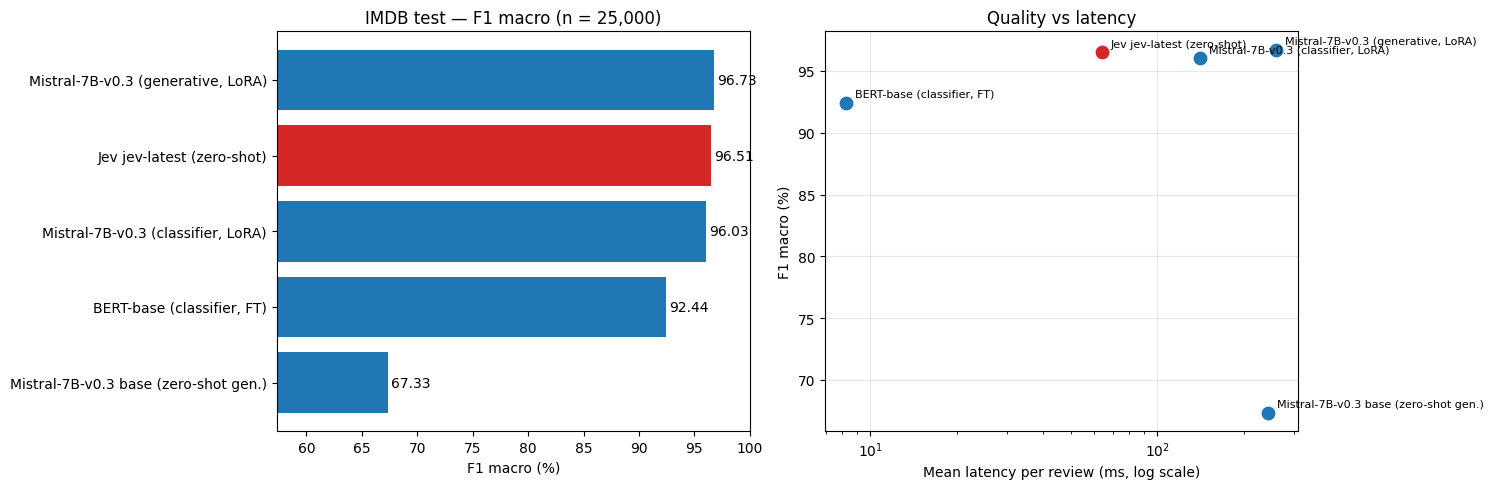

In [25]:
fig, axes = plt.subplots(1, 2, figsize = (15, 5))

d = df_summary.sort_values('F1 macro')
colors = ['#d62728' if m.startswith('Jev') else '#1f77b4' for m in d['Model']]

axes[0].barh(d['Model'], d['F1 macro'], color = colors)
for y, v in enumerate(d['F1 macro']):
  axes[0].text(v + 0.3, y, f'{v:.2f}', va = 'center')
axes[0].set_xlim(max(0, d['F1 macro'].min() - 10), 100)
axes[0].set_xlabel('F1 macro (%)')
axes[0].set_title(f'IMDB test — F1 macro (n = {len(rows_ok):,})')

for _, r in df_summary.iterrows():
  c = '#d62728' if r['Model'].startswith('Jev') else '#1f77b4'
  axes[1].scatter(r['Latency mean (ms)'], r['F1 macro'], s = 80, color = c)
  axes[1].annotate(r['Model'], (r['Latency mean (ms)'], r['F1 macro']), textcoords = 'offset points', xytext = (6, 4), fontsize = 8)
axes[1].set_xscale('log')
axes[1].set_xlabel('Mean latency per review (ms, log scale)')
axes[1].set_ylabel('F1 macro (%)')
axes[1].set_title('Quality vs latency')
axes[1].grid(alpha = 0.3)

plt.tight_layout()
plt.show()

### Error examples
Reviews where the best finetuned model is right and Jev is wrong (useful to understand Jev's failure modes).

In [26]:
best_name = df_summary.loc[~df_summary['Model'].str.startswith('Jev'), 'Model'].iloc[0]
best_pred = models[best_name][1].loc[rows_ok].astype(int)
jev_pred = models[jev_name][1].loc[rows_ok].astype(int)

mask = (best_pred.values == y_true) & (jev_pred.values != y_true)
ex = df.loc[rows_ok[mask], ['text', 'label', f'{col_jev}-label', f'{col_jev}-p-positive']].head(10)
print(f'{mask.sum()} reviews where {best_name} is right and Jev is wrong')
pd.set_option('display.max_colwidth', 300)
ex

382 reviews where Mistral-7B-v0.3 (generative, LoRA) is right and Jev is wrong


,text,label,jev-latest-label,jev-latest-p-positive
1,"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handle...",0,1,0.51
61,"This film features two of my favorite guilty pleasures. Sure, the effects are laughable, the story confused, but just watching Hasselhoff in his Knight Rider days is always fun. I especially like the old hotel they used to shoot this in, it added to what little suspense was mustered. Give it a 3.",0,1,0.59
129,"the usual disclaimer - I do not give 1 star ratings to movies which are harmless, bad, low budget and silly, although they may deserve it. These films are often funny, and get rated 2-4 based sheerly on entertainment value - not as a representation of their exemplary film artistry. This film fit...",0,1,0.89
184,"Just watched on UbuWeb this early experimental short film directed by William Vance and Orson Welles. Yes, you read that right, Orson Welles! Years before he gained fame for radio's ""The War of the Worlds"" and his feature debut Citizen Kane, Welles was a 19-year-old just finding his muse. Beside...",0,1,0.59
188,"I should start off by saying I have something of a love-hate relationship with musicals. Some of them are fantastic, some are downright crap. So I expected Hair to fall into one of those categories. However, it didn't, falling instead in the middle.<br /><br />The songs aren't brilliant, though ...",0,1,0.51
201,"Honest young insurance agent Ronald Reagan (as Eric Gregg) is optimistic, but poor. His wife, scheming Sheila Bromley (as Nona Gregg), longs for the finer things in life. Describing herself as ""not weighted down with tons of righteousness,"" Ms. Bromley begins to spend more money than Mr. Reagan ...",0,1,0.53
308,"I bought this out of curiosity. How did John Carradine (who died in 1988) and Cameron Mitchell (who died in 1994) make appearances in a film made in 1995? Thanks to the miracle of unused film can footage that's probably been sitting on a shelf somewhere for ten years, that's how! You can tell be...",0,1,0.96
311,"I bought Jack-O a number of months ago at a Blockbuster video sale, and at the time I wasn't expecting anything outstanding from it. Upon watching it, I realized I not only got less than I could have ever bargained for, but a whole lot more as well. It seems, strange, I know. And it is. But it's...",0,1,0.87
344,"OK, imagine that every state in the US, nay, every country has exactly the same trees growing and ground foliage. Imagine, also, that a monkey-trapper's camp so far off the beaten track you had to do the first half of the approach by river has a beautifully tarmac'd, perfectly straight road lead...",0,1,0.60
633,"""Submerged"" is definitely NOT ""the worst movie ever"". It does have its flaws, such as borrowed footage, crazy script and non-existent special effects (these are the worst), but it also has some good points too. The acting is surprisingly good, there are LOTS of familiar faces whom you probably k...",0,1,0.77


In [27]:
df_summary.to_csv(f'{path_inference}/summary_all_models_seed_{seed}.csv', index = False)

# 8. Execution Time

In [28]:
end_notebook = time.time()
delta_notebook = end_notebook - start_notebook
hours_notebook, rem_notebook = divmod(delta_notebook, 3600)
minutes_notebook, seconds_notebook = divmod(rem_notebook, 60)
print(f"Execution Notebook: {int(hours_notebook)}h {int(minutes_notebook)}m {seconds_notebook:.2f}s")

Execution Notebook: 0h 4m 49.30s
